Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9079 - loss: 0.3251
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9608 - loss: 0.1363
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9730 - loss: 0.0942
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9762 - loss: 0.0814


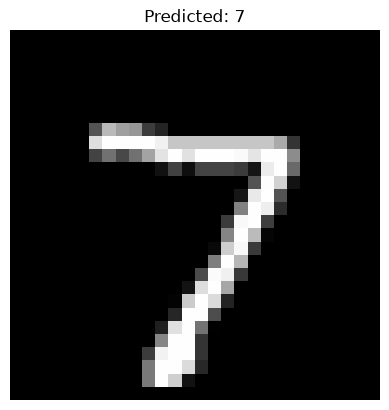

In [1]:

# Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

# Create CNN model
model = tf.keras.Sequential([
    
    tf.keras.layers.Input(shape=(28, 28, 1)),
    
    tf.keras.layers.Conv2D(8, (3, 3), activation='relu'),
    
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    tf.keras.layers.Flatten(),
    
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
model.fit(
    x_train[..., np.newaxis],
    y_train,
    epochs=3
)

# Test model
model.evaluate(
    x_test[..., np.newaxis],
    y_test
)

# Predict one image
index = 0

prediction = model.predict(
    x_test[index:index+1][..., np.newaxis],
    verbose=0
)

predicted_digit = np.argmax(prediction)

# Display image
plt.imshow(x_test[index], cmap='gray')
plt.title(f"Predicted: {predicted_digit}")
plt.axis('off')
plt.show()